In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib
import json
import zipfile
import ast
import re

from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import load_npz

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [18]:
print("Files available in Google Colab:\n")

for filename in os.listdir('/content'):
    print(filename)

Files available in Google Colab:

.config
M2_Module_4_outputs.zip
module_4_outputs
.ipynb_checkpoints
sample_data


In [8]:
from google.colab import files

uploaded = files.upload()

Saving M2_Module_4_outputs.zip to M2_Module_4_outputs.zip


In [12]:
with zipfile.ZipFile(
    '/content/M2_Module_4_outputs.zip',
    'r'
) as zip_ref:

    zip_ref.extractall('/content/module_4_outputs')

print("Previous model files extracted successfully to /content/module_4_outputs!")

Previous model files extracted successfully to /content/module_4_outputs!


In [13]:
print("Extracted files in /content/module_4_outputs:\n")
for root, dirs, files in os.walk('/content/module_4_outputs'):
    for file in files:
        print(os.path.join(root, file))

Extracted files in /content/module_4_outputs:

/content/module_4_outputs/similarity_matrix.npz
/content/module_4_outputs/tfidf_vectorizer.pkl
/content/module_4_outputs/vectorized_dataset.csv
/content/module_4_outputs/tfidf_matrix.npz
/content/module_4_outputs/topics_matrix.npz
/content/module_4_outputs/topics_vectorizer.pkl
/content/module_4_outputs/milestone_3_documentation.txt


In [14]:
output_dir = '/content/module_4_outputs'

# Load the trained TF-IDF vectorizer
tfidf_vectorizer = joblib.load(
    os.path.join(
        output_dir,
        'tfidf_vectorizer.pkl'
    )
)

# Load the TF-IDF matrix
tfidf_matrix = load_npz(
    os.path.join(
        output_dir,
        'tfidf_matrix.npz'
    )
)

# Load the prepared TED Talks dataset
df = pd.read_csv(
    os.path.join(
        output_dir,
        'vectorized_dataset.csv'
    )
)

print("Essential model artifacts loaded successfully!")

Essential model artifacts loaded successfully!


In [17]:
print("MODEL VERIFICATION")
print("=" * 45)

print("Dataset shape:", df.shape)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

print(
    "Vocabulary size:",
    len(tfidf_vectorizer.vocabulary_)
)

print("Total TED Talks:", len(df))

print("\nPrevious Evaluation Results:")

if 'previous_results' in globals():
    for metric, value in previous_results.items():
        print(f"{metric}: {value}")
else:
    print("No previous evaluation results loaded (evaluation_results.json was not in the ZIP archive).")

MODEL VERIFICATION
Dataset shape: (4016, 25)
TF-IDF matrix shape: (4016, 10000)
Vocabulary size: 10000
Total TED Talks: 4016

Previous Evaluation Results:
No previous evaluation results loaded (evaluation_results.json was not in the ZIP archive).


In [19]:
# Define the folder containing the saved model files
output_dir = '/content/module_4_outputs'

# Load the saved vectorizers
tfidf_vectorizer = joblib.load(
    os.path.join(output_dir, 'tfidf_vectorizer.pkl')
)

topics_vectorizer = joblib.load(
    os.path.join(output_dir, 'topics_vectorizer.pkl')
)

# Load the saved matrices
tfidf_matrix = load_npz(
    os.path.join(output_dir, 'tfidf_matrix.npz')
)

topics_matrix = load_npz(
    os.path.join(output_dir, 'topics_matrix.npz')
)

similarity_matrix = load_npz(
    os.path.join(output_dir, 'similarity_matrix.npz')
)

# Load the dataset used for vectorization
df = pd.read_csv(
    os.path.join(output_dir, 'vectorized_dataset.csv')
)

print("All model files loaded successfully!")

All model files loaded successfully!


In [20]:
print("DATASET INFORMATION")
print("-" * 40)
print("Dataset shape:", df.shape)

print("\nMATRIX INFORMATION")
print("-" * 40)
print("TF-IDF Matrix:", tfidf_matrix.shape)
print("Topics Matrix:", topics_matrix.shape)
print("Similarity Matrix:", similarity_matrix.shape)

print("\nVECTORISER INFORMATION")
print("-" * 40)
print("TF-IDF Vectorizer:", type(tfidf_vectorizer))
print("Topics Vectorizer:", type(topics_vectorizer))

print("\nDATASET COLUMNS")
print(df.columns.tolist())

DATASET INFORMATION
----------------------------------------
Dataset shape: (4016, 25)

MATRIX INFORMATION
----------------------------------------
TF-IDF Matrix: (4016, 10000)
Topics Matrix: (4016, 535)
Similarity Matrix: (4016, 4016)

VECTORISER INFORMATION
----------------------------------------
TF-IDF Vectorizer: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
Topics Vectorizer: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>

DATASET COLUMNS
['Talk_Id', 'Title', 'Speaker_1', 'All_Speakers', 'Occupations', 'About_speakers', 'Views', 'Recorded_date', 'Published_date', 'Event', 'Native_lang', 'Available_lang', 'Comments', 'Duration', 'Topics', 'Related_talks', 'URL', 'Description', 'Transcript', 'Topic_Count', 'Title_Word_Count', 'Description_Word_Count', 'Transcript_Word_Count', 'About_speakers_Word_Count', 'Combined_Text']


In [21]:
# Display sample talk information
print("SAMPLE TED TALKS")
display(df[['Talk_Id', 'Title', 'Topics']].head(10))

# Check the data type of Topics
print("\nTOPICS DATA TYPE:")
print(type(df['Topics'].iloc[0]))

# Check missing topic values
print("\nMISSING TOPIC VALUES:")
print(df['Topics'].isnull().sum())

# Display one complete topic value
print("\nSAMPLE TOPIC VALUE:")
print(df['Topics'].iloc[0])

SAMPLE TED TALKS


,Talk_Id,Title,Topics
0,1,Averting the climate crisis,"['alternative energy', 'cars', 'climate change..."
1,92,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,7,Simplicity sells,"['computers', 'entertainment', 'interface desi..."
3,53,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c..."
4,66,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',..."
5,49,Behind the design of Seattle's library,"['architecture', 'collaboration', 'culture', '..."
6,86,Letting go of God,"['Christianity', 'God', 'atheism', 'comedy', '..."
7,94,Let's teach religion -- all religion -- in sch...,"['God', 'atheism', 'brain', 'cognitive science..."
8,71,A life of purpose,"['Christianity', 'God', 'culture', 'happiness'..."
9,55,My wish: A global day of film,"['TED Prize', 'culture', 'entertainment', 'fil..."



TOPICS DATA TYPE:
<class 'str'>

MISSING TOPIC VALUES:
0

SAMPLE TOPIC VALUE:
['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainability', 'technology']


In [23]:
import ast

def safe_literal_eval(val):
    if isinstance(val, str) and val.strip().startswith('[') and val.strip().endswith(']'):
        try:
            return ast.literal_eval(val)
        except (ValueError, SyntaxError):
            return [val]
    elif isinstance(val, list):
        return val
    else:
        return [val] if pd.notnull(val) else []

# Convert string representations of lists into actual Python lists safely
df['Topics'] = df['Topics'].apply(safe_literal_eval)

# Verify the conversion
print("Topics data type:", type(df['Topics'].iloc[0]))

print("\nFirst TED Talk topics:")
print(df['Topics'].iloc[0])

Topics data type: <class 'list'>

First TED Talk topics:
['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainability', 'technology']


In [24]:
# Check whether all topic entries are lists
print("All entries are lists:",
      df['Topics'].apply(lambda x: isinstance(x, list)).all())

# Calculate total number of unique topics
all_topics = set(
    topic
    for topic_list in df['Topics']
    for topic in topic_list
)

print("Total unique topics:", len(all_topics))

All entries are lists: True
Total unique topics: 467


In [25]:
# Convert each talk's topics into a set
topic_sets = df['Topics'].apply(set).tolist()

print("Topic sets created successfully!")

# Display topics of the first TED Talk
print("\nFirst TED Talk:")
print(df['Title'].iloc[0])

print("\nIts topics:")
print(topic_sets[0])

Topic sets created successfully!

First TED Talk:
Averting the climate crisis

Its topics:
{'culture', 'technology', 'sustainability', 'science', 'global issues', 'cars', 'climate change', 'environment', 'alternative energy'}


In [26]:
def get_relevant_talks(query_idx):

    query_topics = topic_sets[query_idx]

    relevant_indices = []

    for idx, topics in enumerate(topic_sets):

        # Exclude the selected talk itself
        if idx == query_idx:
            continue

        # Check whether at least one topic is shared
        if query_topics.intersection(topics):
            relevant_indices.append(idx)

    return relevant_indices

In [27]:
query_idx = 0

relevant_indices = get_relevant_talks(query_idx)

print("Selected TED Talk:")
print(df['Title'].iloc[query_idx])

print("\nTotal relevant TED Talks:", len(relevant_indices))

print("\nFirst 5 relevant TED Talks:")

for idx in relevant_indices[:5]:
    print("-", df['Title'].iloc[idx])

Selected TED Talk:
Averting the climate crisis

Total relevant TED Talks: 2561

First 5 relevant TED Talks:
- The best stats you've ever seen
- Simplicity sells
- Greening the ghetto
- Do schools kill creativity?
- Behind the design of Seattle's library


In [28]:
from sklearn.model_selection import train_test_split

# Split the dataset
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Dataset split completed!")
print("-" * 40)

print("Total talks:", len(df))
print("Training talks:", len(train_df))
print("Testing talks:", len(test_df))

Dataset split completed!
----------------------------------------
Total talks: 4016
Training talks: 3212
Testing talks: 804


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
evaluation_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    dtype=np.float32
)

# Fit only on training data
train_tfidf_matrix = evaluation_vectorizer.fit_transform(
    train_df['Combined_Text']
)

print("TF-IDF model training completed!")
print("----------------------------------")
print("Training talks:", train_tfidf_matrix.shape[0])
print("TF-IDF features:", train_tfidf_matrix.shape[1])
print("Matrix shape:", train_tfidf_matrix.shape)

TF-IDF model training completed!
----------------------------------
Training talks: 3212
TF-IDF features: 10000
Matrix shape: (3212, 10000)


In [31]:
# Convert training and testing topics into sets
train_topic_sets = [
    set(topics) for topics in train_df['Topics']
]

test_topic_sets = [
    set(topics) for topics in test_df['Topics']
]

print("Topic sets created successfully!")
print("----------------------------------")
print("Training topic sets:", len(train_topic_sets))
print("Testing topic sets:", len(test_topic_sets))

# Check a sample
print("\nSample topics from first test talk:")
print(test_topic_sets[0])

Topic sets created successfully!
----------------------------------
Training topic sets: 3212
Testing topic sets: 804

Sample topics from first test talk:
{'algorithm', 'math', 'science', 'science and art', 'collaboration', 'entertainment', 'TEDx', 'composing', 'music'}


In [33]:
def get_top_recommendations(query_text, k=5):

    # Convert the test talk into a TF-IDF vector
    query_vector = evaluation_vectorizer.transform([query_text])

    # Calculate similarity with all training talks
    similarity_scores = cosine_similarity(
        query_vector,
        train_tfidf_matrix
    ).flatten()

    # Get indices of top-k similar talks
    top_indices = np.argsort(similarity_scores)[::-1][:k]

    return top_indices, similarity_scores[top_indices]

# Select the first test talk
sample_query = test_df.iloc[0]['Combined_Text']

# Get top 5 recommendations
top_indices, top_scores = get_top_recommendations(
    sample_query,
    k=5
)

print("Top 5 recommendations generated!")
print("----------------------------------")

for rank, (idx, score) in enumerate(
    zip(top_indices, top_scores), start=1
):
    print(f"\nRank {rank}")
    print("Title:", train_df.iloc[idx]['Title'])
    print("Speaker:", train_df.iloc[idx]['Speaker_1'])
    print("Similarity Score:", round(float(score), 4))

Top 5 recommendations generated!
----------------------------------

Rank 1
Title: Why we love repetition in music
Speaker: Elizabeth Margulis
Similarity Score: 0.3978

Rank 2
Title: How AI could compose a personalized soundtrack to your life
Speaker: Pierre Barreau
Similarity Score: 0.3565

Rank 3
Title: The mad scientist of music
Speaker: Mark Applebaum
Similarity Score: 0.3369

Rank 4
Title: How music makes me a better neuroscientist
Speaker: Indre Viskontas
Similarity Score: 0.3358

Rank 5
Title: La música de las ideas
Speaker: Sergio Feferovich
Similarity Score: 0.3277


In [34]:
def evaluate_recommendation_model(k=5):

    precision_scores = []
    recall_scores = []
    item_recall_scores = []
    ndcg_scores = []
    map_scores = []

    for test_position in range(len(test_df)):

        query_text = test_df.iloc[test_position]['Combined_Text']
        query_topics = test_topic_sets[test_position]

        # Skip talks without topics
        if not query_topics:
            continue

        # Generate top-k recommendations
        top_indices, top_scores = get_top_recommendations(
            query_text, k
        )

        # Identify relevant recommended talks
        relevant_flags = [
            bool(query_topics & train_topic_sets[idx])
            for idx in top_indices
        ]

        # Count all relevant talks in training data
        total_relevant = sum(
            bool(query_topics & topics)
            for topics in train_topic_sets
        )

        if total_relevant == 0:
            continue

        # 1. Precision@K
        precision = sum(relevant_flags) / k

        # 2. Topic-coverage Recall@K (Module 4 definition)
        retrieved_topics = set()

        for idx in top_indices:
            retrieved_topics.update(
                query_topics & train_topic_sets[idx]
            )

        recall = len(retrieved_topics) / len(query_topics)

        # 3. Conventional item-based Recall@K
        item_recall = sum(relevant_flags) / total_relevant

        # 4. NDCG@K
        dcg = sum(
            relevance / np.log2(rank + 2)
            for rank, relevance in enumerate(relevant_flags)
        )

        ideal_relevances = [1] * min(total_relevant, k)

        idcg = sum(
            relevance / np.log2(rank + 2)
            for rank, relevance in enumerate(ideal_relevances)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        # 5. Average Precision@K
        relevant_count = 0
        precision_sum = 0

        for rank, relevance in enumerate(relevant_flags, start=1):

            if relevance:
                relevant_count += 1
                precision_sum += relevant_count / rank

        average_precision = (
            precision_sum / min(total_relevant, k)
        )

        # Store scores
        precision_scores.append(precision)
        recall_scores.append(recall)
        item_recall_scores.append(item_recall)
        ndcg_scores.append(ndcg)
        map_scores.append(average_precision)

    return {
        'Precision@5': np.mean(precision_scores),
        'Recall@5 (Topic Coverage)': np.mean(recall_scores),
        'Item Recall@5': np.mean(item_recall_scores),
        'NDCG@5': np.mean(ndcg_scores),
        'MAP@5': np.mean(map_scores),
        'Evaluated Test Talks': len(precision_scores)
    }

In [35]:
evaluation_results = evaluate_recommendation_model(k=5)

print("TED TALK RECOMMENDATION - EVALUATION RESULTS")
print("=" * 50)

for metric, value in evaluation_results.items():

    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

TED TALK RECOMMENDATION - EVALUATION RESULTS
Precision@5: 0.8636
Recall@5 (Topic Coverage): 0.6727
Item Recall@5: 0.0061
NDCG@5: 0.8695
MAP@5: 0.8207
Evaluated Test Talks: 802


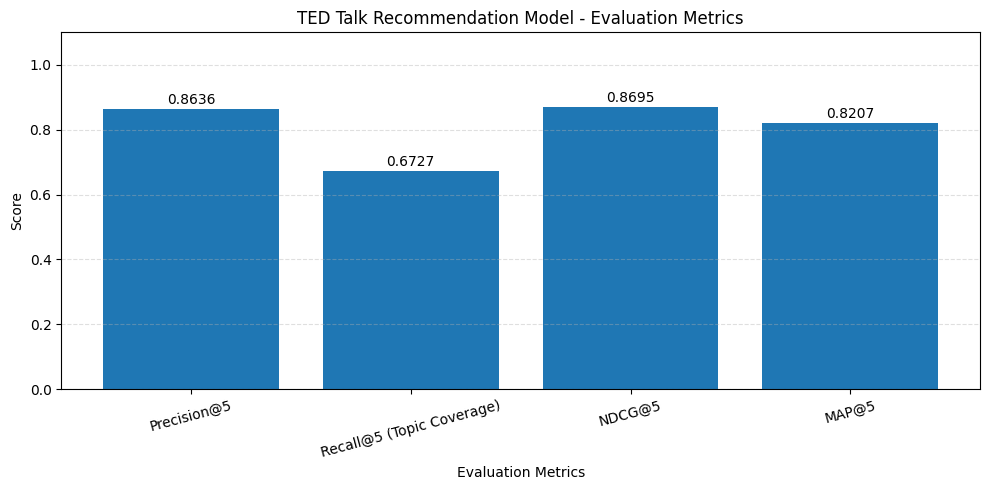

In [36]:
import matplotlib.pyplot as plt

# Select the evaluation metrics
metrics = [
    'Precision@5',
    'Recall@5 (Topic Coverage)',
    'NDCG@5',
    'MAP@5'
]

scores = [
    evaluation_results[metric]
    for metric in metrics
]

# Create bar chart
plt.figure(figsize=(10, 5))

bars = plt.bar(metrics, scores)

# Add score labels
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'{score:.4f}',
        ha='center'
    )

plt.title('TED Talk Recommendation Model - Evaluation Metrics')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [37]:
# Convert topic lists into text
train_topic_text = train_df['Topics'].apply(
    lambda topics: ' '.join(topics)
)

test_topic_text = test_df['Topics'].apply(
    lambda topics: ' '.join(topics)
)

# Create a separate TF-IDF vectorizer
topic_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 2),
    dtype=np.float32
)

# Train using only training topics
train_topic_matrix = topic_vectorizer.fit_transform(
    train_topic_text
)

print("Topic-based TF-IDF model trained!")
print("----------------------------------")
print("Training talks:", train_topic_matrix.shape[0])
print("Topic features:", train_topic_matrix.shape[1])
print("Matrix shape:", train_topic_matrix.shape)

Topic-based TF-IDF model trained!
----------------------------------
Training talks: 3212
Topic features: 5000
Matrix shape: (3212, 5000)


In [38]:
def get_topic_recommendations(query_topics, k=5):

    # Convert query topics into TF-IDF vector
    query_vector = topic_vectorizer.transform(
        [query_topics]
    )

    # Calculate similarity with training talks
    similarity_scores = cosine_similarity(
        query_vector,
        train_topic_matrix
    ).flatten()

    # Select top-k recommendations
    top_indices = np.argsort(similarity_scores)[::-1][:k]

    return top_indices, similarity_scores[top_indices]

In [39]:
def evaluate_topic_model(k=5):

    precision_scores = []
    recall_scores = []
    item_recall_scores = []
    ndcg_scores = []
    map_scores = []

    for test_position in range(len(test_df)):

        query_topics = test_topic_sets[test_position]

        if not query_topics:
            continue

        # Convert topics into text
        query_text = test_topic_text.iloc[test_position]

        # Generate recommendations
        top_indices, top_scores = get_topic_recommendations(
            query_text, k
        )

        # Identify relevant recommendations
        relevant_flags = [
            bool(query_topics & train_topic_sets[idx])
            for idx in top_indices
        ]

        # Count all relevant training talks
        total_relevant = sum(
            bool(query_topics & topics)
            for topics in train_topic_sets
        )

        if total_relevant == 0:
            continue

        # Precision@5
        precision = sum(relevant_flags) / k

        # Topic Coverage Recall@5
        retrieved_topics = set()

        for idx in top_indices:
            retrieved_topics.update(
                query_topics & train_topic_sets[idx]
            )

        recall = len(retrieved_topics) / len(query_topics)

        # Item-based Recall@5
        item_recall = sum(relevant_flags) / total_relevant

        # NDCG@5
        dcg = sum(
            relevance / np.log2(rank + 2)
            for rank, relevance in enumerate(relevant_flags)
        )

        idcg = sum(
            1 / np.log2(rank + 2)
            for rank in range(min(total_relevant, k))
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        # MAP@5
        relevant_count = 0
        precision_sum = 0

        for rank, relevance in enumerate(relevant_flags, start=1):

            if relevance:
                relevant_count += 1
                precision_sum += relevant_count / rank

        average_precision = (
            precision_sum / min(total_relevant, k)
        )

        precision_scores.append(precision)
        recall_scores.append(recall)
        item_recall_scores.append(item_recall)
        ndcg_scores.append(ndcg)
        map_scores.append(average_precision)

    return {
        'Precision@5': np.mean(precision_scores),
        'Recall@5 (Topic Coverage)': np.mean(recall_scores),
        'Item Recall@5': np.mean(item_recall_scores),
        'NDCG@5': np.mean(ndcg_scores),
        'MAP@5': np.mean(map_scores),
        'Evaluated Test Talks': len(precision_scores)
    }

In [40]:
topic_evaluation_results = evaluate_topic_model(k=5)

print("TOPIC-BASED TF-IDF - EVALUATION RESULTS")
print("=" * 50)

for metric, value in topic_evaluation_results.items():

    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

TOPIC-BASED TF-IDF - EVALUATION RESULTS
Precision@5: 0.9988
Recall@5 (Topic Coverage): 0.8380
Item Recall@5: 0.0059
NDCG@5: 0.9988
MAP@5: 0.9988
Evaluated Test Talks: 802


In [41]:
comparison_df = pd.DataFrame({
    'Metric': [
        'Precision@5',
        'Recall@5 (Topic Coverage)',
        'Item Recall@5',
        'NDCG@5',
        'MAP@5'
    ],

    'Combined-text TF-IDF': [
        evaluation_results['Precision@5'],
        evaluation_results['Recall@5 (Topic Coverage)'],
        evaluation_results['Item Recall@5'],
        evaluation_results['NDCG@5'],
        evaluation_results['MAP@5']
    ],

    'Topic-based TF-IDF': [
        topic_evaluation_results['Precision@5'],
        topic_evaluation_results['Recall@5 (Topic Coverage)'],
        topic_evaluation_results['Item Recall@5'],
        topic_evaluation_results['NDCG@5'],
        topic_evaluation_results['MAP@5']
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)

display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Metric,Combined-text TF-IDF,Topic-based TF-IDF
0,Precision@5,0.8636,0.9988
1,Recall@5 (Topic Coverage),0.6727,0.8380
2,Item Recall@5,0.0061,0.0059
3,NDCG@5,0.8695,0.9988
4,MAP@5,0.8207,0.9988


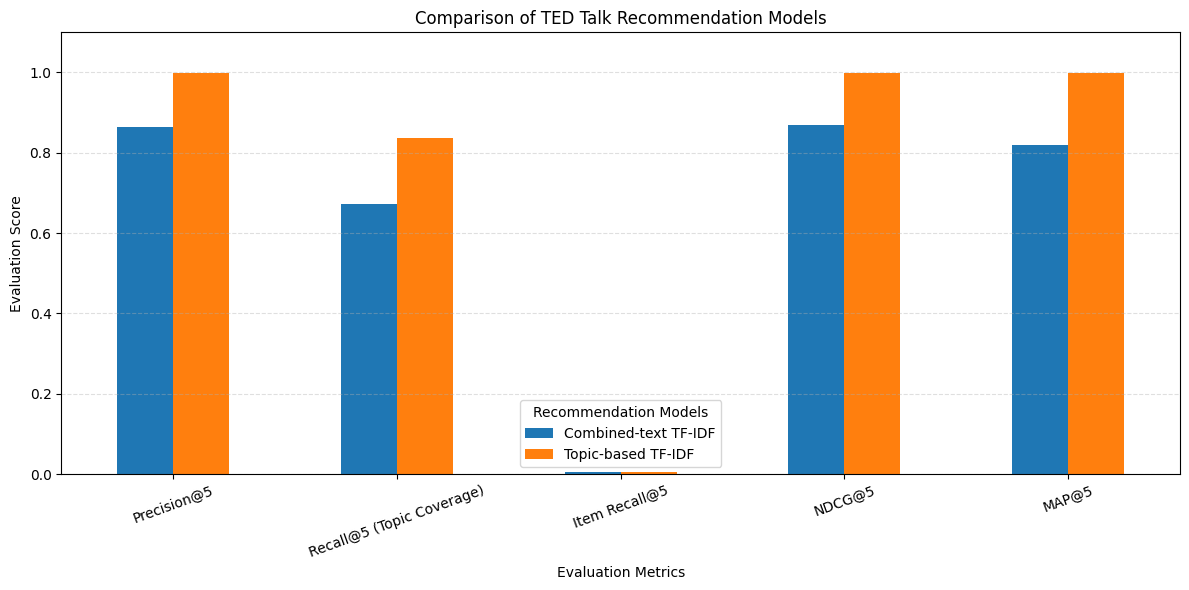

In [42]:
comparison_df.set_index('Metric').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of TED Talk Recommendation Models')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.legend(title='Recommendation Models')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Final Model Selection and Justification
---


After evaluating two content-based recommendation approaches, Combined-text TF-IDF and Topic-based TF-IDF, the Combined-text TF-IDF model was selected as the primary recommendation engine for the TED Talk Recommendation System.

The Combined-text TF-IDF model achieved a Precision@5 of 0.8636, Recall@5 (Topic Coverage) of 0.6727, NDCG@5 of 0.8695 and MAP@5 of 0.8207.

Although Topic-based TF-IDF achieved higher evaluation scores, its recommendations are evaluated using topic overlap, which is also the primary information used by the model. This introduces evaluation bias.

Combined-text TF-IDF considers broader textual information, including talk titles, descriptions and transcripts. Therefore, it offers greater flexibility for identifying meaningful content similarities.

The final system will use Combined-text TF-IDF as its primary recommendation engine, while topic-based filtering will be incorporated as an additional feature to help users explore talks by subject.

Collaborative filtering was not implemented because the available dataset does not contain user interaction information such as ratings, clicks or viewing histories.

